# 2. Variables comportementales et découpage chronologique

Construction des variables temporelles, de vélocité et d'écart au profil de la carte, puis séparation 60 % / 20 % / 20 % dans l'ordre du temps.
Toutes les variables d'historique n'utilisent que les transactions strictement antérieures de la même carte.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().resolve().parent
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 30
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

BLEU = "#2a78d6"
ORANGE = "#eb6834"
VERT = "#1baf7a"
JAUNE = "#eda100"
ROSE = "#e87ba4"

In [2]:
from src import donnees, variables

brut = donnees.charger()
df = variables.construire_variables(brut)
df.shape

(1852394, 35)

In [3]:
colonnes = variables.COLONNES_NUMERIQUES
df[colonnes].describe().T

,count,mean,std,min,25%,50%,75%,max
heure_sin,"1,852,394.0000",-0.1373,0.6929,-1.0000,-0.7977,-0.2738,0.5374,1.0000
heure_cos,"1,852,394.0000",0.0034,0.7078,-1.0000,-0.7041,0.0054,0.7127,1.0000
jour_sin,"1,852,394.0000",-0.0746,0.6851,-0.9749,-0.7818,0.0000,0.4339,0.9749
jour_cos,"1,852,394.0000",0.1472,0.7095,-0.9010,-0.2225,0.6235,0.6235,1.0000
nuit,"1,852,394.0000",0.2348,0.4239,0.0000,0.0000,0.0000,0.0000,1.0000
amt,"1,852,394.0000",70.0636,159.2540,1.0000,9.6400,47.4500,83.1000,"28,948.9000"
log_montant,"1,852,394.0000",3.5317,1.2883,0.6931,2.3646,3.8805,4.4320,10.2733
nb_tx_1h,"1,852,394.0000",0.2000,0.4757,0.0000,0.0000,0.0000,0.0000,8.0000
nb_tx_24h,"1,852,394.0000",4.1108,3.2552,0.0000,2.0000,3.0000,6.0000,35.0000
ratio_moy_30j,"1,851,395.0000",1.0559,2.7417,0.0012,0.1661,0.6718,1.2638,676.3881


## Découpage chronologique

In [4]:
entrainement, validation, test = donnees.decouper_chronologiquement(df)
resume = donnees.resumer({"entrainement": entrainement, "validation": validation, "test": test})
resume

,transactions,fraudes,taux_fraude,debut,fin,cartes
entrainement,1111436,6401,0.0058,2019-01-01 00:00:18,2020-04-07 07:00:14,970
validation,370479,1901,0.0051,2020-04-07 07:00:36,2020-08-25 01:31:21,927
test,370479,1349,0.0036,2020-08-25 01:31:59,2020-12-31 23:59:34,920


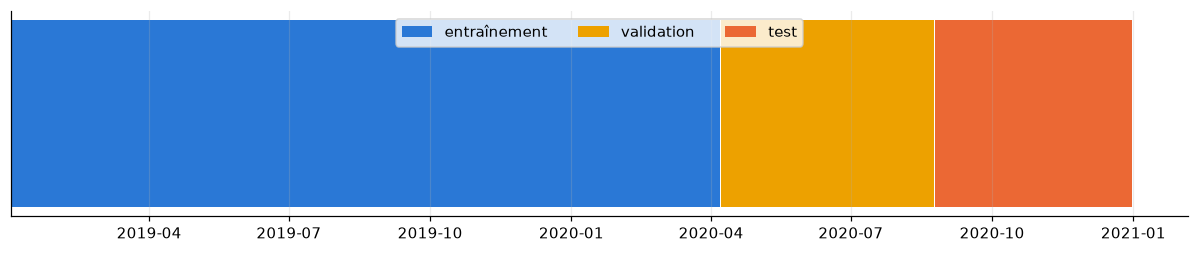

In [5]:
fig, ax = plt.subplots(figsize=(11, 2.4))
for nom, jeu, couleur in (("entraînement", entrainement, BLEU), ("validation", validation, JAUNE), ("test", test, ORANGE)):
    ax.barh(0, (jeu["trans_date_trans_time"].max() - jeu["trans_date_trans_time"].min()).days, left=jeu["trans_date_trans_time"].min(), color=couleur, label=nom, height=0.5)
ax.set_yticks([])
ax.legend(ncol=3, loc="upper center")
fig.tight_layout()

## Vérification de l'absence de fuite

In [6]:
carte = entrainement["cc_num"].value_counts().index[0]
historique = entrainement[entrainement["cc_num"] == carte].sort_values("trans_date_trans_time").reset_index(drop=True)
temps = historique["trans_date_trans_time"].to_numpy().astype("datetime64[s]").astype("int64")
montants = historique["amt"].to_numpy()

attendu_1h = np.array([((temps[:i] >= temps[i] - 3600)).sum() for i in range(len(temps))])
attendu_24h = np.array([((temps[:i] >= temps[i] - 86400)).sum() for i in range(len(temps))])
attendu_ratio = np.array([
    montants[i] / montants[:i][temps[:i] >= temps[i] - 30 * 86400].mean()
    if (temps[:i] >= temps[i] - 30 * 86400).any() else np.nan
    for i in range(len(temps))
])
{
    "transactions_de_la_carte": len(historique),
    "nb_tx_1h_identique": bool((historique["nb_tx_1h"].to_numpy() == attendu_1h).all()),
    "nb_tx_24h_identique": bool((historique["nb_tx_24h"].to_numpy() == attendu_24h).all()),
    "ratio_moy_30j_identique": bool(np.allclose(historique["ratio_moy_30j"].to_numpy(), attendu_ratio, equal_nan=True)),
}

{'transactions_de_la_carte': 2707,
 'nb_tx_1h_identique': True,
 'nb_tx_24h_identique': True,
 'ratio_moy_30j_identique': True}

In [7]:
premieres = entrainement.groupby("cc_num").head(1)
premieres[variables.COLONNES_COMPORTEMENTALES].isna().mean().to_frame("part_manquante_a_la_premiere_transaction")

,part_manquante_a_la_premiere_transaction
nb_tx_1h,0.0000
nb_tx_24h,0.0000
ratio_moy_30j,1.0000
delai_precedent,1.0000
z_montant_30j,1.0000


In [8]:
pd.DataFrame({
    "entrainement": entrainement[variables.COLONNES_COMPORTEMENTALES].isna().mean(),
    "validation": validation[variables.COLONNES_COMPORTEMENTALES].isna().mean(),
    "test": test[variables.COLONNES_COMPORTEMENTALES].isna().mean(),
})

,entrainement,validation,test
nb_tx_1h,0.0000,0.0000,0.0000
nb_tx_24h,0.0000,0.0000,0.0000
ratio_moy_30j,0.0009,0.0000,0.0000
delai_precedent,0.0009,0.0000,0.0000
z_montant_30j,0.0017,0.0001,0.0001


## Pouvoir discriminant des variables

In [9]:
colonnes_etude = ["amt", "nb_tx_1h", "nb_tx_24h", "ratio_moy_30j", "delai_precedent", "z_montant_30j", "distance_km", "nuit"]
resume = entrainement.groupby("is_fraud")[colonnes_etude].median().T
resume.columns = ["mediane_normale", "mediane_fraude"]
resume

,mediane_normale,mediane_fraude
amt,47.2500,390.9000
nb_tx_1h,0.0000,0.0000
nb_tx_24h,3.0000,4.0000
ratio_moy_30j,0.6672,4.3208
delai_precedent,"16,589.0000","4,786.0000"
z_montant_30j,-0.2256,2.1305
distance_km,78.2115,77.8740
nuit,0.0000,1.0000


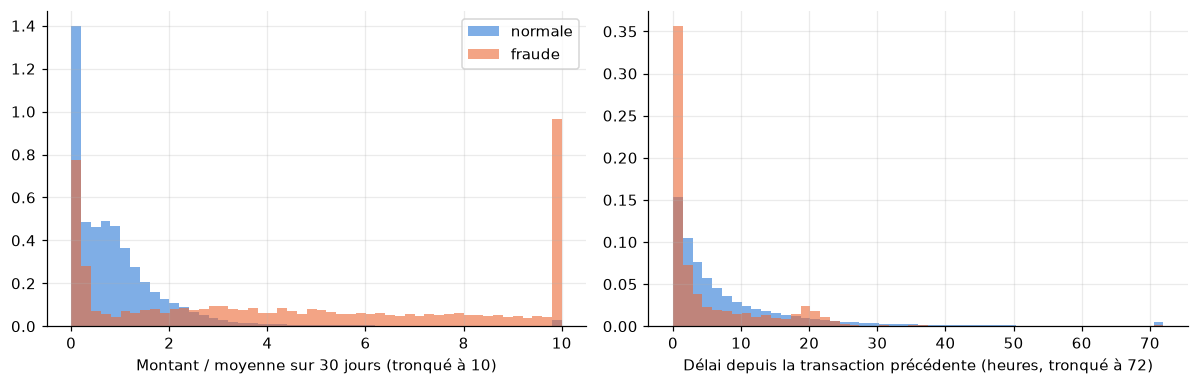

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for classe, couleur, nom in ((0, BLEU, "normale"), (1, ORANGE, "fraude")):
    sous = entrainement[entrainement["is_fraud"] == classe]
    axes[0].hist(sous["ratio_moy_30j"].dropna().clip(upper=10), bins=50, color=couleur, alpha=0.6, density=True, label=nom)
    axes[1].hist((sous["delai_precedent"].dropna() / 3600).clip(upper=72), bins=50, color=couleur, alpha=0.6, density=True, label=nom)
axes[0].set_xlabel("Montant / moyenne sur 30 jours (tronqué à 10)")
axes[1].set_xlabel("Délai depuis la transaction précédente (heures, tronqué à 72)")
axes[0].legend()
fig.tight_layout()

## Choix retenus

- Colonnes écartées : identifiants et quasi-identifiants (nom, rue, ville, code postal, métier, marchand, coordonnées du porteur), ainsi que `unix_time`, dont l'échelle de temps ne correspond pas aux dates (écart de plusieurs années).
- `age` et `genre_f` sont calculés mais ne servent pas au modèle retenu ; la comparaison avec et sans ces variables figure dans le carnet 6.
- Les premières transactions d'une carte n'ont pas d'historique : les valeurs manquantes sont conservées et signalées par un indicateur dans le pipeline linéaire.